<a href="https://colab.research.google.com/github/alaa3wad1305-max/computer-vision/blob/main/CNN_vs_EfficientNet_CIFAR10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()

print("Training images:", x_train.shape)
print("Testing images:", x_test.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 207s 1us/step
Training images: (50000, 32, 32, 3)
Testing images: (10000, 32, 32, 3)


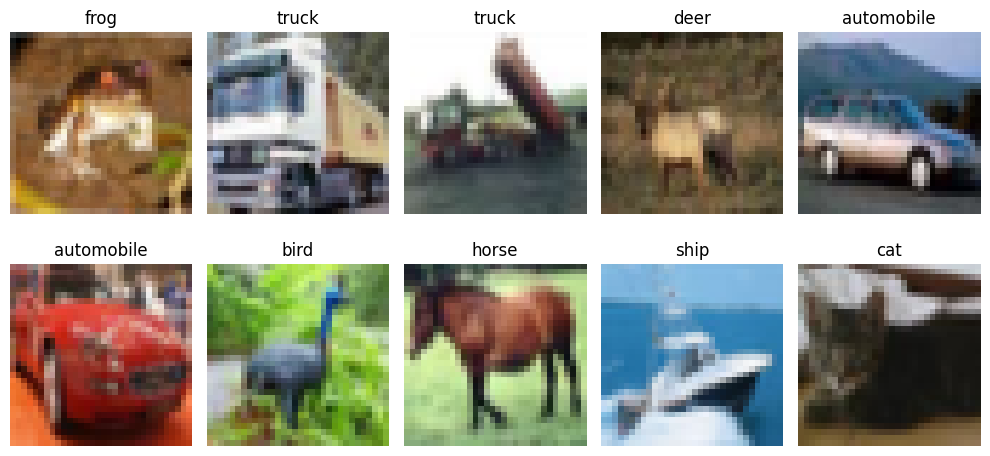

In [3]:
class_names = [
    'airplane', 'automobile', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
]

plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[y_train[i][0]])
    plt.axis('off')

plt.tight_layout()
plt.show()

In [5]:
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0
x_train, x_val = x_train[:-5000], x_train[-5000:]
y_train, y_val = y_train[:-5000], y_train[-5000:]

In [13]:
cnn_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(32, 32, 3)),

    tf.keras.layers.Conv2D(32, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(128, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(10, activation='softmax')
])

cnn_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 4, 4, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 2, 2, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 160,202 (625.79 KB)

 Trainable params: 160,202 (625.79 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:
cnn_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [15]:
import time

start_time = time.time()

cnn_history = cnn_model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_data=(x_val, y_val)
)

cnn_training_time = time.time() - start_time

print("CNN Training Time:", cnn_training_time)

Epoch 1/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 10s 9ms/step - accuracy: 0.3841 - loss: 1.6689 - val_accuracy: 0.5030 - val_loss: 1.3608
Epoch 2/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.5325 - loss: 1.2994 - val_accuracy: 0.5948 - val_loss: 1.1628
Epoch 3/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.5912 - loss: 1.1540 - val_accuracy: 0.6344 - val_loss: 1.0312
Epoch 4/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.6323 - loss: 1.0415 - val_accuracy: 0.6534 - val_loss: 0.9875
Epoch 5/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.6662 - loss: 0.9570 - val_accuracy: 0.6654 - val_loss: 0.9561
Epoch 6/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.6901 - loss: 0.8888 - val_accuracy: 0.6674 - val_loss: 0.9599
Epoch 7/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.7074 - loss: 0.8350 - val_accuracy: 0.6874 - val_loss: 0.8816
Epoch 8/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.7244 - loss: 0.7829 - val_accuracy: 0

In [16]:
cnn_loss, cnn_accuracy = cnn_model.evaluate(x_test, y_test)

print("CNN Test Accuracy:", cnn_accuracy)
print("CNN Test Loss:", cnn_loss)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.6942 - loss: 0.8994
CNN Test Accuracy: 0.6941999793052673
CNN Test Loss: 0.8993743062019348


In [10]:
print("Test images shape:", x_test.shape)
print("Test labels shape:", y_test.shape)

predictions = cnn_model.predict(x_test[:10])

predicted_classes = np.argmax(predictions, axis=1)
true_classes = y_test[:10].flatten()

print("Predicted:", predicted_classes)
print("Actual:", true_classes)

print("Predicted names:")
print([class_names[i] for i in predicted_classes])

print("Actual names:")
print([class_names[i] for i in true_classes])

Test images shape: (10000, 32, 32, 3)
Test labels shape: (10000, 1)
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
Predicted: [2 2 2 2 2 2 2 2 2 2]
Actual: [3 8 8 0 6 6 1 6 3 1]
Predicted names:
['bird', 'bird', 'bird', 'bird', 'bird', 'bird', 'bird', 'bird', 'bird', 'bird']
Actual names:
['cat', 'ship', 'ship', 'airplane', 'frog', 'frog', 'automobile', 'frog', 'cat', 'automobile']


In [11]:
print("X train range:", x_train.min(), x_train.max())
print("Y train classes:", np.unique(y_train, return_counts=True))

print("\nTrainable parameters:")
cnn_model.summary()

print("\nFirst 10 prediction probabilities:")
print(cnn_model.predict(x_test[:10]))

X train range: 0.0 0.003921569
Y train classes: (array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9], dtype=uint8), array([4507, 4512, 4521, 4481, 4525, 4471, 4512, 4515, 4468, 4488]))

Trainable parameters:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 2, 2, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 480,608 (1.83 MB)

 Trainable params: 160,202 (625.79 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 320,406 (1.22 MB)


First 10 prediction probabilities:
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
[[0.09969522 0.10019685 0.10128023 0.09998393 0.09974431 0.10009571
  0.10035042 0.10082082 0.0983123  0.09952018]
 [0.09969522 0.10019685 0.10128023 0.09998393 0.09974431 0.10009571
  0.10035042 0.10082082 0.0983123  0.09952018]
 [0.09969522 0.10019685 0.10128023 0.09998393 0.09974431 0.10009571
  0.10035042 0.10082082 0.0983123  0.09952018]
 [0.09969522 0.10019685 0.10128023 0.09998393 0.09974431 0.10009571
  0.10035042 0.10082082 0.0983123  0.09952018]
 [0.09969522 0.10019685 0.10128023 0.09998393 0.09974431 0.10009571
  0.10035042 0.10082082 0.0983123  0.09952018]
 [0.09969522 0.10019685 0.10128023 0.09998393 0.09974431 0.10009571
  0.10035042 0.10082082 0.0983123  0.09952018]
 [0.09969522 0.10019685 0.10128023 0.09998393 0.09974431 0.10009571
  0.10035042 0.10082082 0.0983123  0.09952018]
 [0.09969522 0.10019685 0.10128023 0.09998393 0.09974431 0.10009571
  0.10035042 0.10082082 0.0983123  0.09952018]
 [0.09

In [12]:
# Reload CIFAR-10 to restore original images
(x_train_original, y_train_original), (x_test_original, y_test_original) = tf.keras.datasets.cifar10.load_data()

# Normalize only once
x_train_original = x_train_original.astype("float32") / 255.0
x_test_original = x_test_original.astype("float32") / 255.0

# Create training and validation sets
x_train = x_train_original[:-5000]
y_train = y_train_original[:-5000]

x_val = x_train_original[-5000:]
y_val = y_train_original[-5000:]

x_test = x_test_original
y_test = y_test_original

print("Train range:", x_train.min(), x_train.max())
print("Test range:", x_test.min(), x_test.max())

Train range: 0.0 1.0
Test range: 0.0 1.0


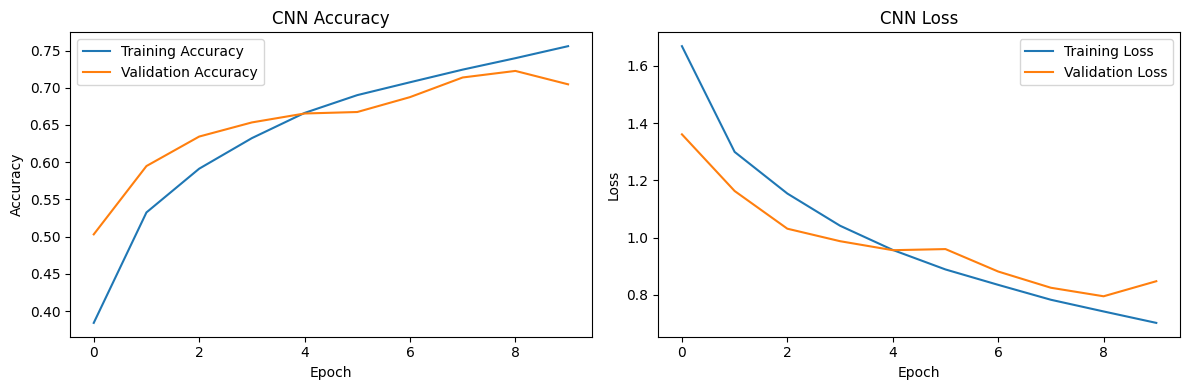

In [17]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(cnn_history.history['accuracy'], label='Training Accuracy')
plt.plot(cnn_history.history['val_accuracy'], label='Validation Accuracy')
plt.title('CNN Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(cnn_history.history['loss'], label='Training Loss')
plt.plot(cnn_history.history['val_loss'], label='Validation Loss')
plt.title('CNN Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [18]:
base_model = tf.keras.applications.EfficientNetB0(
    weights='imagenet',
    include_top=False,
    input_shape=(96, 96, 3)
)

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


In [19]:
base_model.trainable = False

In [20]:
efficientnet_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(96, 96, 3)),

    base_model,

    tf.keras.layers.GlobalAveragePooling2D(),

    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(10, activation='softmax')
])

efficientnet_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 3, 3, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,062,381 (15.50 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [21]:
def prepare_image(image, label):
    image = tf.image.resize(image, (96, 96))
    image = image * 255.0
    return image, label


batch_size = 32

train_ds = tf.data.Dataset.from_tensor_slices(
    (x_train, y_train)
)

train_ds = train_ds.map(
    prepare_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

train_ds = train_ds.shuffle(1000).batch(batch_size).prefetch(tf.data.AUTOTUNE)


val_ds = tf.data.Dataset.from_tensor_slices(
    (x_val, y_val)
)

val_ds = val_ds.map(
    prepare_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

val_ds = val_ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)


test_ds = tf.data.Dataset.from_tensor_slices(
    (x_test, y_test)
)

test_ds = test_ds.map(
    prepare_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_ds = test_ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)

In [22]:
efficientnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [23]:
start_time = time.time()

efficientnet_history = efficientnet_model.fit(
    train_ds,
    epochs=5,
    validation_data=val_ds
)

efficientnet_training_time = time.time() - start_time

print("EfficientNet Training Time:", efficientnet_training_time)

Epoch 1/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 101s 40ms/step - accuracy: 0.7950 - loss: 0.6312 - val_accuracy: 0.8510 - val_loss: 0.4440
Epoch 2/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 18s 13ms/step - accuracy: 0.8343 - loss: 0.4917 - val_accuracy: 0.8516 - val_loss: 0.4283
Epoch 3/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 20s 14ms/step - accuracy: 0.8409 - loss: 0.4727 - val_accuracy: 0.8592 - val_loss: 0.4115
Epoch 4/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 18s 13ms/step - accuracy: 0.8451 - loss: 0.4589 - val_accuracy: 0.8588 - val_loss: 0.4080
Epoch 5/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 19s 13ms/step - accuracy: 0.8424 - loss: 0.4588 - val_accuracy: 0.8592 - val_loss: 0.4064
EfficientNet Training Time: 176.9684762954712


In [24]:
efficientnet_loss, efficientnet_accuracy = efficientnet_model.evaluate(test_ds)

print("EfficientNet Test Accuracy:", efficientnet_accuracy)
print("EfficientNet Test Loss:", efficientnet_loss)

313/313 ━━━━━━━━━━━━━━━━━━━━ 25s 80ms/step - accuracy: 0.8555 - loss: 0.4228
EfficientNet Test Accuracy: 0.8554999828338623
EfficientNet Test Loss: 0.42283305525779724


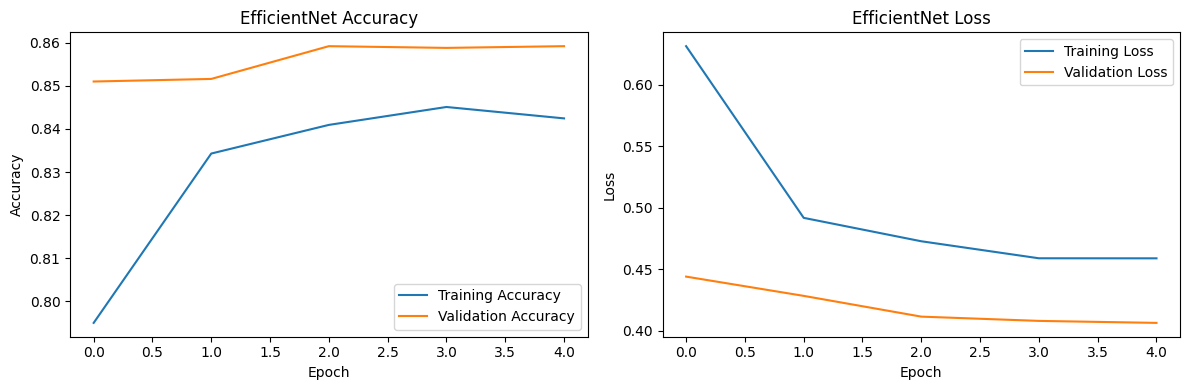

In [25]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(efficientnet_history.history['accuracy'], label='Training Accuracy')
plt.plot(efficientnet_history.history['val_accuracy'], label='Validation Accuracy')
plt.title('EfficientNet Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(efficientnet_history.history['loss'], label='Training Loss')
plt.plot(efficientnet_history.history['val_loss'], label='Validation Loss')
plt.title('EfficientNet Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [26]:
results = {
    "Model": ["CNN from Scratch", "EfficientNetB0"],
    "Test Accuracy": [cnn_accuracy, efficientnet_accuracy],
    "Test Loss": [cnn_loss, efficientnet_loss],
    "Training Time (seconds)": [
        cnn_training_time,
        efficientnet_training_time
    ]
}

import pandas as pd

results_df = pd.DataFrame(results)
results_df

,Model,Test Accuracy,Test Loss,Training Time (seconds)
0,CNN from Scratch,0.6942,0.899374,40.651313
1,EfficientNetB0,0.8555,0.422833,176.968476


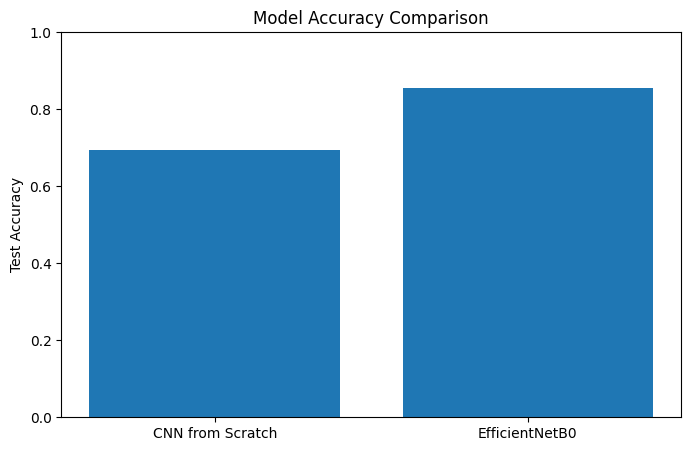

In [27]:
plt.figure(figsize=(8, 5))

plt.bar(
    results_df["Model"],
    results_df["Test Accuracy"]
)

plt.title("Model Accuracy Comparison")
plt.ylabel("Test Accuracy")
plt.ylim(0, 1)

plt.show()